In [47]:
#projectile simulator: d^2x / dt^2 = 0 and d^2y / dt^2 = -g

import matplotlib.pyplot as plt

#without air drag

def f(x, v):
    return v, 0

def g(y, u):
    return u, -9.8

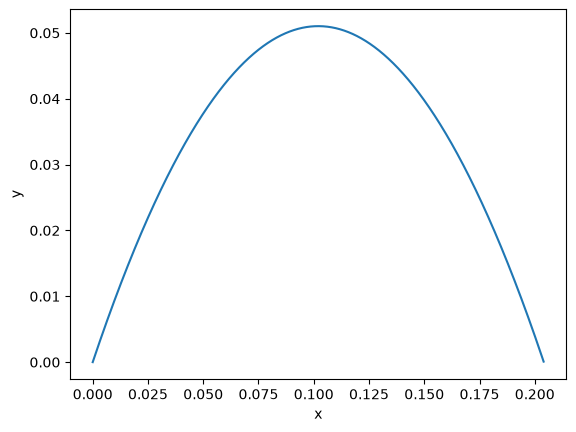

In [48]:
#using rk4

#initial time conditions
t0 = 0
tmax = 10

#time step
h = 0.0001

#initial displacement and velocity conditions
x0 = 0
v0 = 1
y0 = 0
u0 = 1

time = [t0]
displacement_x = [x0]
velocity_x = [v0]
displacement_y = [y0]
velocity_y = [u0]

while t0 < tmax - 1e-12:
    k1x, k1v = f(x0, v0)
    k2x, k2v = f(x0 + h/2 * k1x, v0 + h/2 * k1v)
    k3x, k3v = f(x0 + h/2 * k2x, v0 + h/2 * k2v)
    k4x, k4v = f(x0 + h * k3x, v0 + h * k3v)    
    v0 = v0 + h * (k1v + 2 * k2v + 2 * k3v + k4v) / 6  
    x0 = x0 + h * (k1x + 2 * k2x + 2 * k3x + k4x) / 6

    k1y, k1u = g(y0, u0)
    k2y, k2u = g(y0 + h/2 * k1y, u0 + h/2 * k1u)
    k3y, k3u = g(y0 + h/2 * k2y, u0 + h/2 * k2u)
    k4y, k4u = g(y0 + h * k3y, u0 + h * k3u)    
    u0 = u0 + h * (k1u + 2 * k2u + 2 * k3u + k4u) / 6  
    y0 = y0 + h * (k1y + 2 * k2y + 2 * k3y + k4y) / 6

    if(y0 < 0):
        break
    
    t0 = t0 + h

    time.append(t0)
    displacement_x.append(x0)
    velocity_x.append(v0)
    displacement_y.append(y0)
    velocity_y.append(u0)

plt.plot(displacement_x, displacement_y)
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [49]:
#with linear air drag

#d^2x / dt^2 = - b / m * dx / dt and d^2y / dt^2 = -g - b / m * dy / dt

m = 1
b = 1

def linear_drag_x(x, v):
    return v, - b / m * v

def linear_drag_y(y, u):
    return u, -9.8 - b / m * u

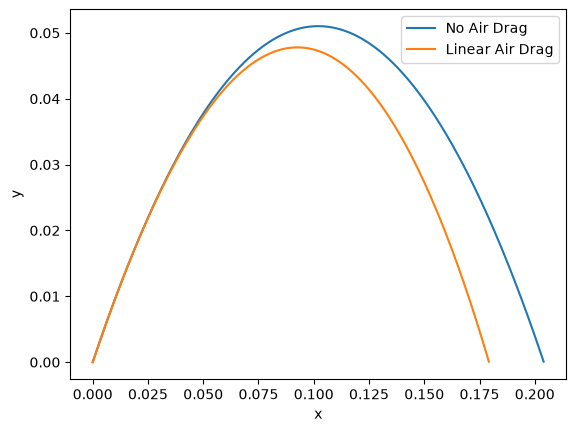

In [50]:
#using rk4

#initial time conditions
t0 = 0

#initial displacement and velocity conditions
x0 = 0
v0 = 1
y0 = 0
u0 = 1

linear_displacement_x = [x0]
linear_velocity_x = [v0]
linear_displacement_y = [y0]
linear_velocity_y = [u0]

while t0 < tmax - 1e-12:
    k1x, k1v = linear_drag_x(x0, v0)
    k2x, k2v = linear_drag_x(x0 + h/2 * k1x, v0 + h/2 * k1v)
    k3x, k3v = linear_drag_x(x0 + h/2 * k2x, v0 + h/2 * k2v)
    k4x, k4v = linear_drag_x(x0 + h * k3x, v0 + h * k3v)    
    v0 = v0 + h * (k1v + 2 * k2v + 2 * k3v + k4v) / 6  
    x0 = x0 + h * (k1x + 2 * k2x + 2 * k3x + k4x) / 6

    k1y, k1u = linear_drag_y(y0, u0)
    k2y, k2u = linear_drag_y(y0 + h/2 * k1y, u0 + h/2 * k1u)
    k3y, k3u = linear_drag_y(y0 + h/2 * k2y, u0 + h/2 * k2u)
    k4y, k4u = linear_drag_y(y0 + h * k3y, u0 + h * k3u)    
    u0 = u0 + h * (k1u + 2 * k2u + 2 * k3u + k4u) / 6  
    y0 = y0 + h * (k1y + 2 * k2y + 2 * k3y + k4y) / 6

    if(y0 <= 0):
        break
    
    t0 = t0 + h

    linear_displacement_x.append(x0)
    linear_velocity_x.append(v0)
    linear_displacement_y.append(y0)
    linear_velocity_y.append(u0)

plt.plot(displacement_x, displacement_y)
plt.plot(linear_displacement_x, linear_displacement_y)
plt.legend(["No Air Drag", "Linear Air Drag"])
plt.xlabel("x")
plt.ylabel("y")
plt.show()
plt.show()

In [51]:
#with quadratic air drag

#d^2x / dt^2 = - c / m * [(dx / dt)^2 + (dy / dt)^2]^(1 / 2) * dx / dt
#d^2y / dt^2 = - 9.8 - c / m * [(dx / dt)^2 + (dy / dt)^2]^(1 / 2) * dy / dt

c = 1

def quad_drag_x(x, v, v_mod):
    return v, - c / m * v_mod * v

def quad_drag_y(y, u, v_mod):
    return u, -9.8 - c / m * v_mod * u

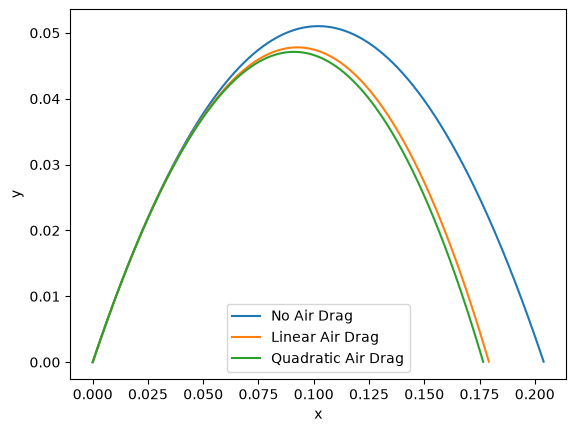

In [52]:
#using rk4

import numpy as np

#initial time conditions
t0 = 0

#initial displacement and velocity conditions
x0 = 0
v0 = 1
y0 = 0
u0 = 1

quad_displacement_x = [x0]
quad_velocity_x = [v0]
quad_displacement_y = [y0]
quad_velocity_y = [u0]

v_mod = np.sqrt(v0**2 + u0**2)

while t0 < tmax - 1e-12:
    k1x, k1v = quad_drag_x(x0, v0, v_mod)
    k2x, k2v = quad_drag_x(x0 + h/2 * k1x, v0 + h/2 * k1v, v_mod)
    k3x, k3v = quad_drag_x(x0 + h/2 * k2x, v0 + h/2 * k2v, v_mod)
    k4x, k4v = quad_drag_x(x0 + h * k3x, v0 + h * k3v, v_mod)    
    v0 = v0 + h * (k1v + 2 * k2v + 2 * k3v + k4v) / 6  
    x0 = x0 + h * (k1x + 2 * k2x + 2 * k3x + k4x) / 6

    k1y, k1u = quad_drag_y(y0, u0, v_mod)
    k2y, k2u = quad_drag_y(y0 + h/2 * k1y, u0 + h/2 * k1u, v_mod)
    k3y, k3u = quad_drag_y(y0 + h/2 * k2y, u0 + h/2 * k2u, v_mod)
    k4y, k4u = quad_drag_y(y0 + h * k3y, u0 + h * k3u, v_mod)    
    u0 = u0 + h * (k1u + 2 * k2u + 2 * k3u + k4u) / 6  
    y0 = y0 + h * (k1y + 2 * k2y + 2 * k3y + k4y) / 6

    if(y0 <= 0):
        break
    
    t0 = t0 + h
    v_mod = np.sqrt(v0**2 + u0**2)

    quad_displacement_x.append(x0)
    quad_velocity_x.append(v0)
    quad_displacement_y.append(y0)
    quad_velocity_y.append(u0)

plt.plot(displacement_x, displacement_y)
plt.plot(linear_displacement_x, linear_displacement_y)
plt.plot(quad_displacement_x, quad_displacement_y)
plt.legend(["No Air Drag", "Linear Air Drag", "Quadratic Air Drag"])
plt.xlabel("x")
plt.ylabel("y")
plt.show()
plt.show()